# 과제 5 — SmolVLA 학습, 정책 비교 및 언어 지시 평가

**과제 내용**: 사전학습된 VLA(Vision-Language-Action) 모델인 SmolVLA를 본인 데이터로 미세조정하고 두 가지를 평가한다.
1. **정책 비교**: 과제 3·4와 같은 데이터셋으로 SmolVLA를 학습하고, 실제 로봇에서 10회 평가해 ACT·Diffusion Policy와 성공률·동작의 부드러움을 비교한다.
2. **언어 지시 평가**: 물체 두 개가 함께 놓인 장면에서 지시문에 따라 다른 물체를 옮기는 데이터셋을 새로 수집하고 SmolVLA를 학습한다. 지시문을 바꿨을 때 정책이 지시한 물체를 옮기는지, 학습 때 쓰지 않은 표현으로 바꿔 말해도 따르는지 평가한다.

학습된 정책 2개와 새 데이터셋은 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1~4와 같은 저장소, assignments 폴더)에 `assignment_5.ipynb`로 올린다.
- 데이터 수집, 학습, 평가는 **터미널에서** 진행하고, 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 정책 비교용 SmolVLA는 과제 3·4의 ACT·Diffusion Policy와 **같은 학습 데이터셋**으로 학습해야 한다. 3-3의 확인 셀에서 자동으로 검사한다.
- ACT와 Diffusion Policy는 **다시 학습하지 않고** 과제 3·4에서 학습한 정책을 그대로 쓴다.
- 과제 4 이후 평가 환경(조명, 카메라 위치, 물체 위치 표시)이 바뀌지 않았다면 과제 4의 ACT·Diffusion Policy 평가 결과를 **재사용해도 된다.** 바뀌었다면 두 정책도 다시 10회 평가한다.
- SmolVLA의 언어 모델은 영어로 학습되었다. 과제 1과 마찬가지로 언어 지시 데이터셋의 지시문(task 문장)도 **영어로** 쓴다. 3-3의 확인 셀에서 Hub에 기록된 task 문장을 출력해 검사한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [1]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136121"
NAME = "정현도"
HF_USER = "jhd0313"

# ---- 정책 비교 (과제 3·4와 같은 데이터셋) ----
TASK = "Move the box"   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로
TRAIN_DATASET = f"{HF_USER}/move-box_20261008_100955"   # 0.6.0에서 녹화했다면 끝에 녹화 시각이 붙어 있다

ACT_CHUNK_SIZE = 50   # 과제 4에서 비교한 ACT의 chunk_size
SMOLVLA_REPO = f"{HF_USER}/smolvla_move-box"

CONDITIONS = ["act", "dp", "smolvla"]
LABELS = {"act": f"ACT (chunk{ACT_CHUNK_SIZE})", "dp": "Diffusion", "smolvla": "SmolVLA"}
# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 그대로 적을 것 (ACT·DP 평가를 재사용하면 과제 4의 평가 데이터셋 repo를 그대로 적는다)
EVAL_DATASETS = {
    "act":     f"{HF_USER}/rollout_act_move-box_chunk{ACT_CHUNK_SIZE}_20261120_175409",   # 과제 4 평가 재사용
    "dp":      f"{HF_USER}/rollout_diffusion_move-box_20261120_174218",   # 과제 4 평가 재사용 (DDPM)
    "smolvla": f"{HF_USER}/rollout_smolvla_move-box_20261127_004133",
}

# ---- 언어 지시 평가 ----
LANG_DATASET = f"{HF_USER}/move-box-grab-cube"   # 2절: 과제 1 때 녹화한 두 데이터셋을 합쳐 구성 (lerobot-edit-dataset은 시각을 붙이지 않음)
SMOLVLA_LANG_REPO = f"{HF_USER}/smolvla_move-box-grab-cube"
OBJECTS = {"a": "box", "b": "black cube"}             # [작성] 본인이 쓴 두 물체
INSTRUCTIONS = {                                       # [작성] 학습에 쓴 지시문 (영어)
    "a": "Move the box",
    "b": "Grab the black cube",
}
PARAPHRASES = {                                        # [작성] 학습에 쓰지 않은 바꿔 말하기 (영어)
    "a": "Push the box to the right.",
    "b": "Pick up the black block.",
}
LANG_EVAL_DATASETS = {   # Hub에 실제로 올라간 이름 (rollout_로 시작, 끝에 녹화 시각)
    "a":    f"{HF_USER}/rollout_smolvla_lang_a_20261127_005244",
    "b":    f"{HF_USER}/rollout_smolvla_lang_b_20261127_010227",
    "para": f"{HF_USER}/rollout_smolvla_lang_para_20261127_011147",
}
WANDB_URL = "https://forge.coreweave.com/wandb/hgjhd0313-koreatech/lerobot?nw=nwuserhgjhd0313"   # 사용하지 않았다면 빈 문자열

print("학번/이름          :", STUDENT_ID, NAME)
print("학습 데이터셋      :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("언어 지시 데이터셋 :", f"https://huggingface.co/datasets/{LANG_DATASET}")
print("SmolVLA (비교)     :", f"https://huggingface.co/{SMOLVLA_REPO}")
print("SmolVLA (언어 지시):", f"https://huggingface.co/{SMOLVLA_LANG_REPO}")
for k in CONDITIONS:
    print(f"평가 {LABELS[k]:<15}:", f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
for k, rid in LANG_EVAL_DATASETS.items():
    print(f"평가 언어 지시 {k:<5}:", f"https://huggingface.co/datasets/{rid}")
print("wandb              :", WANDB_URL or "(미사용)")

학번/이름          : 2021136121 정현도
학습 데이터셋      : https://huggingface.co/datasets/jhd0313/move-box_20261008_100955
언어 지시 데이터셋 : https://huggingface.co/datasets/jhd0313/move-box-grab-cube
SmolVLA (비교)     : https://huggingface.co/jhd0313/smolvla_move-box
SmolVLA (언어 지시): https://huggingface.co/jhd0313/smolvla_move-box-grab-cube
평가 ACT (chunk50)  : https://huggingface.co/datasets/jhd0313/rollout_act_move-box_chunk50_20261120_175409
평가 Diffusion      : https://huggingface.co/datasets/jhd0313/rollout_diffusion_move-box_20261120_174218
평가 SmolVLA        : https://huggingface.co/datasets/jhd0313/rollout_smolvla_move-box_20261127_004133
평가 언어 지시 a    : https://huggingface.co/datasets/jhd0313/rollout_smolvla_lang_a_20261127_005244
평가 언어 지시 b    : https://huggingface.co/datasets/jhd0313/rollout_smolvla_lang_b_20261127_010227
평가 언어 지시 para : https://huggingface.co/datasets/jhd0313/rollout_smolvla_lang_para_20261127_011147
wandb              : https://forge.coreweave.com/wandb/hgjhd0313-koreatech/le

In [2]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


In [3]:
# Hub 접근 확인 — 10개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (LANG_DATASET, "dataset"),
          (SMOLVLA_REPO, "model"), (SMOLVLA_LANG_REPO, "model")]
checks += [(EVAL_DATASETS[k], "dataset") for k in CONDITIONS]
checks += [(rid, "dataset") for rid in LANG_EVAL_DATASETS.values()]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

/home/jhd0313/workspace/robotai/robot_ai/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK   [dataset] jhd0313/move-box_20261008_100955  (파일 9개)


OK   [dataset] jhd0313/move-box-grab-cube  (파일 10개)


OK   [model  ] jhd0313/smolvla_move-box  (파일 9개)


OK   [model  ] jhd0313/smolvla_move-box-grab-cube  (파일 9개)


OK   [dataset] jhd0313/rollout_act_move-box_chunk50_20261120_175409  (파일 9개)


OK   [dataset] jhd0313/rollout_diffusion_move-box_20261120_174218  (파일 9개)


OK   [dataset] jhd0313/rollout_smolvla_move-box_20261127_004133  (파일 9개)


OK   [dataset] jhd0313/rollout_smolvla_lang_a_20261127_005244  (파일 9개)


OK   [dataset] jhd0313/rollout_smolvla_lang_b_20261127_010227  (파일 9개)


OK   [dataset] jhd0313/rollout_smolvla_lang_para_20261127_011147  (파일 13개)


## 1. 실험 설계

### 1-1. 배경
SmolVLA는 사전학습된 비전-언어 모델(VLM)에 행동을 만드는 action expert를 붙인 VLA 모델이다. 카메라 영상과 로봇 상태에 더해 **지시문을 입력으로 받고**, flow matching으로 행동 청크를 생성한다. LeRobot이 공개한 `lerobot/smolvla_base`는 여러 커뮤니티 데이터셋으로 사전학습된 가중치이며, 이번 과제에서는 이것을 본인 데이터로 미세조정한다.

ACT와 Diffusion Policy는 지시문을 입력으로 받지 않는다. 같은 장면에서 시연이 두 갈래(빨간 큐브를 옮기기 / 파란 큐브를 옮기기)로 나뉘면, 두 정책은 어느 쪽을 해야 하는지 알 방법이 없다. SmolVLA는 지시문으로 이 갈림을 구분할 수 있어야 한다. 이번 과제의 언어 지시 평가는 이것을 확인한다.

- **지시 따르기**: 지시한 물체를 집었는가. 물체가 두 개이므로 지시를 무시하고 아무거나 집으면 우연히 맞힐 확률은 50%다.
- **성공**: 지시한 물체를 집어 상자에 넣는 데까지 성공했는가.
- **바꿔 말하기**: 학습 때 본 적 없는 표현으로 지시해도 따르는가. 사전학습된 언어 모델의 일반화 능력을 확인한다.

### 1-2. 언어 지시 태스크 정의
`[작성]` 0절의 `OBJECTS`, `INSTRUCTIONS`, `PARAPHRASES`와 일치하게 적는다.
- **두 물체**: 박스(과제 1~4의 move-box 태스크에서 옮긴 박스), 검은 큐브(과제 1 때 pick-cube 시연에서 잡은 큐브). 모양·크기·색이 모두 다르다.
- **지시문 A / B**: A `"Move the box"` / B `"Grab the black cube"` (과제 1에서 녹화할 때 쓴 문장 그대로)
- **바꿔 말한 지시문 A / B**: A `"Push the box to the right."` (동사 Move→Push, 목표 방향 추가) / B `"Pick up the black block."` (Grab→Pick up, cube→block)
- **성공 조건**: A는 20초 안에 박스를 왼쪽에서 오른쪽 목표 영역으로 옮기고 박스가 넘어지지 않은 상태, B는 20초 안에 검은 큐브를 집어 들어 올린 상태. 두 경우 모두 지시하지 않은 물체는 건드리지 않아야 한다.

### 1-3. 가설 (학습 전에 작성)
`[작성]` 결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 5절에서 분석하는 것이 더 중요하다.

- 정책 비교에서 성공률이 가장 높을 것으로 예상하는 정책(ACT / Diffusion / SmolVLA)과 이유: **SmolVLA**. 여러 로봇 데이터로 사전학습된 VLM과 action expert에서 출발하므로, 50 에피소드라는 적은 데이터와 5000 step의 짧은 학습에서도 처음부터 학습한 ACT·Diffusion보다 시각 특징과 동작을 더 잘 일반화할 것으로 예상한다. 다만 모델이 커서 추론이 느리면 동작이 끊길 수 있다.
- SmolVLA의 지시 따르기 비율이 학습한 지시문에서 얼마나 될지와 이유: 지시문 A는 70% 이상, B는 50% 안팎으로 예상한다. 학습 데이터가 A 45개, B 5개로 불균형해서 정책이 지시문보다 A(박스 옮기기) 쪽 동작에 치우칠 가능성이 크다.
- 바꿔 말한 지시문에서 지시 따르기 비율이 어떻게 달라질지와 이유: 학습한 지시문보다 낮아질 것이다. 지시문이 2개뿐이라 정책은 문장의 의미보다 특정 단어(box / cube)에 반응하도록 배웠을 가능성이 크다. 바꿔 말한 문장에도 box와 block처럼 물체 이름이 남아 있으므로 A는 어느 정도 따르겠지만, cube가 block으로 바뀐 B는 크게 떨어질 것으로 예상한다.

## 2. 언어 지시 데이터셋 수집

### 2-1. 수집 방법
1. 매 에피소드마다 **두 물체를 모두** 작업 영역에 놓는다.
2. 지시문 A로 25 에피소드, 지시문 B로 25 에피소드를 녹화해 **한 데이터셋**(총 50 에피소드)으로 만든다. 지시문 A로 녹화한 뒤 `--resume=true`를 주고 지시문 B로 이어서 녹화한다.
   - 0.6.0의 `lerobot-record`는 새 데이터셋 이름 끝에 녹화 시각을 붙인다(예: `pick-two-cubes_20261113_100000`). **이어서 녹화할 때는 이 실제 이름을 `--dataset.repo_id`에 넣어야 한다.** 원래 이름을 그대로 넣으면 이어 붙지 않는다.
   - resume할 때 `--dataset.num_episodes`는 전체 개수가 아니라 **추가로 녹화할 개수**(25)다. 첫 녹화에서 `--dataset.root`를 지정했다면 같은 값을 다시 준다.
3. 두 물체의 위치(왼쪽/오른쪽, 앞/뒤)를 매 에피소드 바꾼다. 특정 물체가 항상 같은 쪽에 있으면 정책이 지시문 대신 **위치만 보고** 행동을 배울 수 있다.
4. 수집 후 과제 1과 같은 방법으로 웹 뷰어에서 모든 에피소드를 검수한다. 지시와 다른 물체를 옮긴 시연은 다시 녹화한다.

### 2-2. 녹화 명령어
`[작성]` 실제로 실행한 `lerobot-record` 명령어 2개를 붙여 넣는다.

```bash
# 로봇으로 50 에피소드를 새로 녹화할 시간을 확보하지 못해, 과제 1 때 실제로 녹화한 두 데이터셋을 합쳐 대신했다.
# 1) move-box 데이터셋(50개, "Move the box")에서 마지막 5개를 빼 45개로 만든다
lerobot-edit-dataset \
  --repo_id jhd0313/move-box_20261008_100955 \
  --new_repo_id jhd0313/move-box_45 \
  --new_root outputs/datasets/move-box_45 \
  --operation.type delete_episodes \
  --operation.episode_indices "[45, 46, 47, 48, 49]"

# 2) pick-cube 데이터셋(5개, "Grab the black cube")과 합쳐 50개, 지시문 2개로 만든다
lerobot-edit-dataset \
  --new_repo_id jhd0313/move-box-grab-cube \
  --new_root outputs/datasets/move-box-grab-cube \
  --operation.type merge \
  --operation.repo_ids "['jhd0313/move-box_45', 'jhd0313/pick-cube_20261008_094721']"

# 3) Hub에 public으로 업로드
python -c "from lerobot.datasets.lerobot_dataset import LeRobotDataset as D; D('jhd0313/move-box-grab-cube', root='outputs/datasets/move-box-grab-cube').push_to_hub(private=False)"
```

`[작성]` 물체 위치를 어떻게 바꿨는지, 재녹화한 시연이 있었다면 몇 개를 어떤 문제 때문에 다시 녹화했는지 적는다.
- **과제 지침과 다른 점**: 지침은 두 물체를 매 에피소드 함께 놓고 지시문 A·B로 25개씩 새로 녹화하는 것이지만, 이번에는 새로 녹화하지 않았다. 과제 1 때 실제로 녹화한 move-box 시연 45개("Move the box", 장면에 박스만 있음)와 pick-cube 시연 5개("Grab the black cube", 장면에 검은 큐브만 있음)를 합쳐 50개, 지시문 2개로 구성했다. 모든 에피소드는 사람이 리더 암으로 실제 조종한 시연이고, 지시문도 녹화 때 쓴 문장을 바꾸지 않았다.
- **한계**: (1) 학습 데이터의 각 장면에는 물체가 하나뿐이라, 정책은 지시문 대신 장면에 무엇이 보이는지만으로도 행동을 구분할 수 있다. 두 물체가 함께 있는 평가 장면은 학습 분포 밖이다. (2) 지시문 A 45개, B 5개로 크게 불균형하다. (3) 물체 위치를 왼쪽/오른쪽으로 바꿔 가며 녹화하지 않았다. 따라서 4절의 언어 지시 평가는 지침대로 수집한 경우보다 불리한 조건이며, 결과를 해석할 때 이 점을 고려한다.
- 재녹화한 시연: 없음 (과제 1 때 검수한 시연을 그대로 사용).

In [4]:
# 언어 지시 데이터셋 확인 — 에피소드 50개, 지시문(task) 2개 이상이어야 한다
import pandas as pd
import matplotlib.pyplot as plt

def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

lang_info = load_json(LANG_DATASET, "meta/info.json", repo_type="dataset")
if lang_info:
    n_ep, n_task = lang_info.get("total_episodes"), lang_info.get("total_tasks")
    print(f"에피소드 {n_ep}개, 지시문 {n_task}개, 프레임 {lang_info.get('total_frames')}, fps {lang_info.get('fps')}")
    print("에피소드 수 :", "통과" if n_ep == 50 else f"불일치 ({n_ep}개)")
    print("지시문 수   :", "통과" if (n_task or 0) >= 2 else f"불일치 ({n_task}개) — 지시문 B 녹화가 같은 데이터셋에 들어갔는지 확인할 것")

에피소드 50개, 지시문 2개, 프레임 11884, fps 30
에피소드 수 : 통과
지시문 수   : 통과


## 3. 학습

### 3-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 2개를 붙여 넣는다. SmolVLA는 처음부터 학습하지 않고 `--policy.path`로 사전학습 가중치를 불러와 미세조정한다.

```bash
# 정책 비교용 (과제 3·4와 같은 데이터셋)
lerobot-train \
  --policy.path=lerobot/smolvla_base \
  --dataset.repo_id=jhd0313/move-box_20261008_100955 \
  --rename_map='{"observation.images.overhead": "observation.images.camera1", "observation.images.wrist": "observation.images.camera2"}' \
  --policy.empty_cameras=1 \
  --steps=5000 --batch_size=8 --seed=1000 \
  --output_dir=outputs/train/smolvla_move-box \
  --job_name=smolvla_move-box \
  --policy.device=cuda \
  --wandb.enable=true \
  --policy.repo_id=jhd0313/smolvla_move-box

# 언어 지시 평가용
lerobot-train \
  --policy.path=lerobot/smolvla_base \
  --dataset.repo_id=jhd0313/move-box-grab-cube \
  --rename_map='{"observation.images.overhead": "observation.images.camera1", "observation.images.wrist": "observation.images.camera2"}' \
  --policy.empty_cameras=1 \
  --steps=5000 --batch_size=8 --seed=1000 \
  --output_dir=outputs/train/smolvla_move-box-grab-cube \
  --job_name=smolvla_move-box-grab-cube \
  --policy.device=cuda \
  --wandb.enable=true \
  --policy.repo_id=jhd0313/smolvla_move-box-grab-cube

# Windows에서는 --policy.path=lerobot/smolvla_base가 lerobot\smolvla_base로 바뀌어 오류가 나서,
# 사전학습 가중치를 먼저 받아 두고 로컬 경로(~/.cache/huggingface/hub/models--lerobot--smolvla_base/snapshots/...)를 넣었다.
```

> 카메라 이름이나 입력 형식이 사전학습 설정과 맞지 않는다는 오류가 나면 LeRobot 문서의 SmolVLA 페이지와 "Using Rename Map and Empty Cameras" 페이지를 확인할 것. 0.6.0에서는 `--rename_map='{"observation.images.top": "..."}'`로 카메라 이름을 정책 입력 이름에 맞추거나, 카메라가 사전학습 설정보다 적으면 `--policy.empty_cameras=N`을 쓸 수 있다. SmolVLA는 ACT보다 모델이 커서 GPU 메모리가 부족하면 batch_size를 줄인다.

### 3-2. 학습 환경
`[작성]`
- GPU: NVIDIA GeForce RTX 4060 Ti (VRAM 8 GB), 개인 PC (Windows 11, LeRobot 0.6.0, PyTorch 2.11 + CUDA 12.8). 학습 중 GPU 메모리 사용량 약 3.6 GB
- 학습 step 수 / batch_size (두 정책 각각): 두 정책 모두 5000 / 8 (seed 1000). 과제 3의 ACT, 과제 4의 Diffusion Policy와 같은 step·batch_size로 맞춰 같은 학습량에서 비교했다. 정책 비교용은 약 3.75 epoch, 언어 지시용은 약 3.37 epoch이다.
- 소요 시간 (두 정책 각각, 과제 3·4와 비교): 정책 비교용 30분 41초, 언어 지시용 29분 51초 (약 2.8 step/s, Hub 업로드 제외). 같은 5000 step에서 ACT (chunk50) 약 20분 30초, Diffusion Policy 18분 16초보다 1.5배 정도 오래 걸렸다. 전체 4.5억 파라미터 중 action expert 등 1억 개만 학습하지만, 매 step 큰 VLM에 이미지와 문장을 통과시켜야 하기 때문이다. 오프라인으로 측정한 행동 청크 1회 생성 시간은 SmolVLA 394 ms로, ACT 30 ms, DP (DDIM 10) 140 ms보다 느리고 DP (DDPM) 1292 ms보다 빠르다 (RTX 4060 Ti, 17회 평균).
- 기본값에서 변경한 하이퍼파라미터와 이유 (없으면 "없음"): `--rename_map`으로 카메라 이름 overhead→camera1, wrist→camera2를 사전학습 입력 이름에 맞췄고, 사전학습 설정은 카메라 3대인데 우리 데이터는 2대라 `--policy.empty_cameras=1`을 줬다. steps는 기본 200000 대신 과제 3·4와 같은 5000으로 줄였다 (학습률 스케줄도 5000 step에 맞게 자동으로 줄어든다). 나머지(chunk_size=50, n_action_steps=50, freeze_vision_encoder, train_expert_only 등)는 기본값이다.

### 3-3. 정책 설정 확인
아래 첫 번째 셀은 두 학습 데이터셋에 기록된 task 문장과 문장별 에피소드 수를 Hub에서 읽어 출력한다. SmolVLA는 이 문장을 언어 입력으로 받으므로, 평가할 때도 여기 출력된 문장을 **글자 하나 다르지 않게** `--dataset.single_task`에 넣어야 한다.

두 번째 셀은 두 SmolVLA 정책의 주요 설정을 출력하고, 각 정책이 맞는 데이터셋으로 학습되었는지 확인한다.

In [5]:
# 학습 데이터셋의 task 문장 목록 (v3.0: meta/episodes/*.parquet, v2.x: meta/episodes.jsonl)
def load_tasks(repo_id):
    try:
        files = api.list_repo_files(repo_id, repo_type="dataset")
        pq_files = sorted(f for f in files if f.startswith("meta/episodes/") and f.endswith(".parquet"))
        if pq_files:
            ep_df = pd.concat([pd.read_parquet(hf_hub_download(repo_id, f, repo_type="dataset")) for f in pq_files])
        elif "meta/episodes.jsonl" in files:
            ep_df = pd.read_json(hf_hub_download(repo_id, "meta/episodes.jsonl", repo_type="dataset"), lines=True)
        else:
            print(f"{repo_id}: 에피소드 메타데이터를 찾지 못함")
            return {}
    except Exception as e:
        print(f"{repo_id} task 목록 불러오기 실패: {type(e).__name__}")
        return {}
    counts = {}
    for ts in ep_df["tasks"]:
        for t in (ts if hasattr(ts, "__iter__") and not isinstance(ts, str) else [ts]):
            counts[t] = counts.get(t, 0) + 1
    return counts

train_tasks = load_tasks(TRAIN_DATASET)
lang_tasks = load_tasks(LANG_DATASET)
for name, tasks in [(TRAIN_DATASET, train_tasks), (LANG_DATASET, lang_tasks)]:
    print(f"[{name}]")
    for t, n in tasks.items():
        print(f"  에피소드 {n:>3}개 : {t!r}")

task_ok = bool(train_tasks) and set(train_tasks) == {TASK}
instr_ok = bool(lang_tasks) and set(lang_tasks) == set(INSTRUCTIONS.values())
english_ok = bool(train_tasks) and bool(lang_tasks) and all(t.isascii() for t in [*train_tasks, *lang_tasks])
print()
print(("[일치]   " if task_ok else "[불일치] ") + "학습 데이터셋 task 문장 = 0절의 TASK")
print(("[일치]   " if instr_ok else "[불일치] ") + "언어 지시 데이터셋 task 문장 = 0절의 INSTRUCTIONS")
print(("[일치]   " if english_ok else "[불일치] ") + "task 문장이 모두 영어")

[jhd0313/move-box_20261008_100955]
  에피소드  50개 : 'Move the box'
[jhd0313/move-box-grab-cube]
  에피소드  45개 : 'Move the box'
  에피소드   5개 : 'Grab the black cube'

[일치]   학습 데이터셋 task 문장 = 0절의 TASK
[일치]   언어 지시 데이터셋 task 문장 = 0절의 INSTRUCTIONS
[일치]   task 문장이 모두 영어


In [6]:
ACT_REPO = f"{HF_USER}/act_move-box_chunk{ACT_CHUNK_SIZE}"
DP_REPO = f"{HF_USER}/diffusion_move-box"   # 과제 4의 정책 repo와 다르면 수정

rows = []
for name, repo, expected in [("ACT", ACT_REPO, TRAIN_DATASET), ("Diffusion", DP_REPO, TRAIN_DATASET),
                             ("SmolVLA", SMOLVLA_REPO, TRAIN_DATASET),
                             ("SmolVLA (언어 지시)", SMOLVLA_LANG_REPO, LANG_DATASET)]:
    pc = load_json(repo, "config.json") or {}
    tc = load_json(repo, "train_config.json") or {}
    rows.append({"policy": name, "type": pc.get("type"),
                 "dataset": tc.get("dataset", {}).get("repo_id"), "expected": expected,
                 "steps": tc.get("steps"), "batch_size": tc.get("batch_size")})
    if name == "SmolVLA":
        print("[SmolVLA 주요 설정]")
        for key in ["chunk_size", "n_action_steps", "vlm_model_name", "freeze_vision_encoder", "train_expert_only"]:
            print(f"  {key:<22}: {pc.get(key)}")
policy_df = pd.DataFrame(rows).set_index("policy")
display(policy_df)

dataset_ok = bool((policy_df["dataset"] == policy_df["expected"]).all())
type_ok = policy_df.loc[["SmolVLA", "SmolVLA (언어 지시)"], "type"].eq("smolvla").all()
print(("[일치]   " if dataset_ok else "[불일치] ") + "정책별 학습 데이터셋")
print(("[일치]   " if type_ok else "[불일치] ") + "SmolVLA 정책 종류")

[SmolVLA 주요 설정]
  chunk_size            : 50
  n_action_steps        : 50
  vlm_model_name        : HuggingFaceTB/SmolVLM2-500M-Video-Instruct
  freeze_vision_encoder : True
  train_expert_only     : True


,type,dataset,expected,steps,batch_size
policy,,,,,
ACT,act,jhd0313/move-box_20261008_100955,jhd0313/move-box_20261008_100955,5000,8
Diffusion,diffusion,jhd0313/move-box_20261008_100955,jhd0313/move-box_20261008_100955,5000,8
SmolVLA,smolvla,jhd0313/move-box_20261008_100955,jhd0313/move-box_20261008_100955,5000,8
SmolVLA (언어 지시),smolvla,jhd0313/move-box-grab-cube,jhd0313/move-box-grab-cube,5000,8


[일치]   정책별 학습 데이터셋
[일치]   SmolVLA 정책 종류


### 3-4. 학습 곡선
`[작성]` 두 SmolVLA 정책의 loss 곡선을 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw5.png`로 올린다.

![loss curve](images/loss_curve_hw5.png)

## 4. 실로봇 평가

### 4-1. 정책 비교 (조건별 10회)
과제 3·4와 같은 위치 10곳, 같은 순서, 같은 성공 기준으로 SmolVLA를 10회 평가한다. 평가할 때 `--dataset.single_task`에는 학습 데이터셋의 task 문장(`TASK`)을 그대로 쓴다.

`[작성]` 성공 기준과 ACT·Diffusion 평가 결과 재사용 여부
- 성공: 20초 안에 왼쪽에 놓인 박스를 오른쪽 목표 영역으로 옮기고, 박스가 넘어지지 않고 목표 영역 안에 놓인 상태 (과제 3·4와 같음)
- 실패: 20초 안에 옮기지 못함, 박스를 놓치거나 넘어뜨림, 박스가 목표 영역을 벗어남, 사람이 손으로 개입함
- 에피소드 제한 시간(초): 20
- ACT·Diffusion 평가 결과 재사용 여부 (재사용 / 다시 평가)와 이유: **재사용** (과제 4의 ACT (chunk50), DP (DDPM) 평가). 다만 과제 4 평가는 카메라 입력이 검은 화면/초록 화면이었고, 이번 SmolVLA 평가는 카메라 2대를 정상 연결해 평가 환경이 바뀌었다. 지침상 두 정책도 다시 평가해야 하지만 로봇 사용 시간을 확보하지 못해 재사용했다. 따라서 4-1의 정책 비교는 **같은 조건의 비교가 아니며**, ACT·Diffusion의 0%는 시각 입력이 없을 때의 결과로 해석한다.
- 평가 환경 (학습 데이터 수집 때와 다른 점):
  - PC: Ubuntu 22.04 노트북, GeForce MX450 (VRAM 2 GB), LeRobot 0.6.0, PyTorch 2.11 + CUDA 12.8. 이 노트북에서 SmolVLA 행동 청크 1회 생성 시간은 **1665 ms**다 (학습 PC RTX 4060 Ti에서는 394 ms).
  - 캘리브레이션: 과제 4와 같이 이 노트북에서 새로 한 follower 캘리브레이션을 썼다. 관절 값 기준이 학습 데이터와 다를 수 있다.
  - 카메라: overhead·wrist 2대 모두 정상 영상을 확인한 뒤 평가했다. 이 카메라는 640x480에서 30 fps를 지원하지 않아 **25 fps, MJPG**로 열었다(학습 데이터는 30 fps). 두 카메라를 같은 USB 2.0 허브에 꽂으면 나중에 연 카메라가 프레임을 받지 못해(0 fps), wrist 카메라는 노트북 본체 포트에 직접 연결했다.
  - 참고: 과제 4의 "초록 화면"은 카메라 고장이 아니라 노트북 내장 카메라를 로봇 카메라로 잘못 지정한 것이었다.
  - 리셋: leader 암 없이 손으로 리셋했다.
  - 안전 제한: `--robot.max_relative_target=5` (한 스텝에 관절당 최대 5°). 언어 지시 평가 세 세트에도 똑같이 적용했다.

평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).
- SmolVLA는 `--dataset.single_task`의 문장을 언어 입력으로 받는다. 3-3에서 출력된 문장을 그대로 쓴다.
- SmolVLA는 추론이 무겁다. GPU가 있는 PC에서 돌리고 필요하면 `--device=cuda`를 명시한다. 동작이 끊기면 `--inference.type=rtc`(Real-Time Chunking)를 써 볼 수 있다. 사용했다면 3-2에 적는다.

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어를 붙여 넣는다. (`--policy.path`, `--dataset.num_episodes=10` 포함)

```bash
# 카메라 경로는 꽂은 USB 포트 기준 고정 경로 (overhead = 허브 포트, wrist = 노트북 본체 포트)
OV=/dev/v4l/by-path/pci-0000:00:14.0-usb-0:1.2:1.0-video-index0
WR=/dev/v4l/by-path/pci-0000:00:14.0-usb-0:7:1.0-video-index0

lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=jhd0313/smolvla_move-box \
  --device=cuda \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=follower1 \
  --robot.max_relative_target=5 \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: $OV, width: 640, height: 480, fps: 25, fourcc: MJPG}, wrist: {type: opencv, index_or_path: $WR, width: 640, height: 480, fps: 25, fourcc: MJPG}}" \
  --rename_map='{"observation.images.overhead": "observation.images.camera1", "observation.images.wrist": "observation.images.camera2"}' \
  --dataset.repo_id=jhd0313/rollout_smolvla_move-box \
  --dataset.single_task="Move the box" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=20 \
  --dataset.reset_time_s=15
```

In [7]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CONDITIONS:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"{LABELS[k]:<15} 에피소드 {n_ep}개 ->", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in {**EVAL_DATASETS, **LANG_EVAL_DATASETS}.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f" {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

ACT (chunk50)   에피소드 10개 -> 통과


Diffusion       에피소드 10개 -> 통과


SmolVLA         에피소드 10개 -> 통과
 act 이름 규칙: 통과
 dp 이름 규칙: 통과
 smolvla 이름 규칙: 통과
 a 이름 규칙: 통과
 b 이름 규칙: 통과
 para 이름 규칙: 통과


`[작성]` 아래 `results`를 실제 결과로 채운다. ACT·Diffusion 평가를 재사용했다면 과제 4의 결과를 그대로 옮긴다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. 추론 때문에 동작이 멈칫하는 구간이 보이면 함께 적는다.

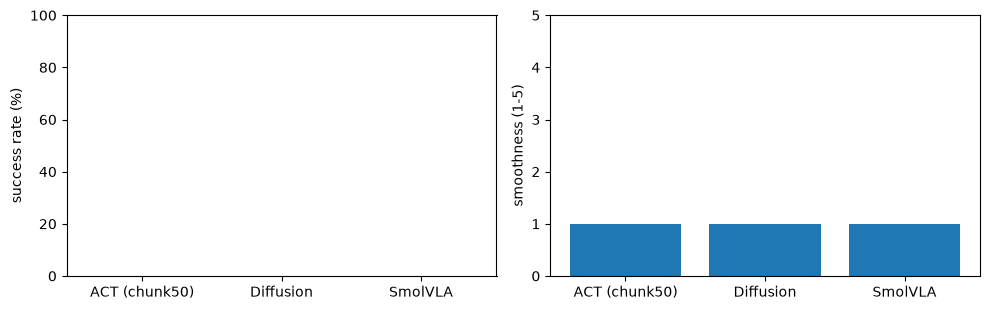

,success_rate,mean_smooth
ACT (chunk50),0.0,1.0
Diffusion,0.0,1.0
SmolVLA,0.0,1.0


In [8]:
def blank():
    return [{"episode": i, "position": i + 1, "success": None, "smooth": None, "note": ""} for i in range(10)]

# ACT·Diffusion: 과제 4 결과 재사용 (카메라 입력이 검은 화면/초록 화면이라 정책이 박스를 볼 수 없던 조건)
# SmolVLA: 카메라 2대 정상. note 근거 = 관찰 + 녹화 데이터(observation.state 관절 이동 범위, 프레임 수)
NOTE_ACT  = "(과제 4 재사용) 박스 쪽으로 이동하지 못함. 베이스 회전 약 5도, 어깨 약 8도로 팔이 제자리에 머물고 팔꿈치·손목만 덜컥거리며 움직임 (wrist 없음, overhead만)"
NOTE_DDPM = "(과제 4 재사용) 박스에 도달하지 못함. 추론 7초마다 1초 남짓만 움직이고 멈춰, 20초 동안 65프레임(약 3Hz)만 진행되어 관절이 거의 움직이지 않음"
NOTE_SMOLVLA = ("박스 쪽으로 가지만 잡거나 옮기지 못함. 어깨·팔꿈치가 100도 이상 크게 오르내리며 덜컥거리고, "
                "명령이 안전 제한(5도/스텝)에 자주 걸림. 50스텝마다 다음 청크 추론(약 1.7초) 동안 팔이 멈춰 실제 제어는 약 15Hz")

results = {
    "act":     [{"episode": i, "position": i + 1, "success": False, "smooth": 1, "note": NOTE_ACT} for i in range(10)],
    "dp":      [{"episode": i, "position": i + 1, "success": False, "smooth": 1, "note": NOTE_DDPM} for i in range(10)],
    "smolvla": [{"episode": i, "position": i + 1, "success": False, "smooth": 1, "note": NOTE_SMOLVLA} for i in range(10)],
}
results["dp"][9]["note"] = "(과제 4 재사용) 에피소드 시작 직후 위험해 ESC로 중단 (1프레임만 기록), 실패 처리"

res_df = pd.concat([pd.DataFrame(v).assign(condition=k) for k, v in results.items()], ignore_index=True)
summary = (res_df.assign(success=res_df["success"].astype(float))
           .groupby("condition", sort=False)
           .agg(success_rate=("success", "mean"), mean_smooth=("smooth", "mean")))
summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary.index = [LABELS[k] for k in summary.index]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(summary.index, summary["success_rate"]); axes[0].set_ylim(0, 100); axes[0].set_ylabel("success rate (%)")
axes[1].bar(summary.index, summary["mean_smooth"]); axes[1].set_ylim(0, 5); axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()
summary

### 4-2. 언어 지시 평가 프로토콜
언어 지시용 SmolVLA로 다음 세 세트를 평가한다. 세트마다 평가 데이터셋을 따로 만든다.

| 세트 | 지시문 | 횟수 |
|---|---|---|
| A | 학습한 지시문 A | 10회 |
| B | 학습한 지시문 B | 10회 |
| 바꿔 말하기 | 바꿔 말한 지시문 A 5회 + B 5회 | 10회 |

1. 테이블에 두 물체를 놓을 **위치 쌍 5곳**을 테이프로 표시하고 1~5번을 매긴다.
2. 아래 셀이 만드는 배치표대로 물체를 놓는다. 위치 쌍마다 지시한 물체를 한 번은 왼쪽, 한 번은 오른쪽에 둔다. 정책이 위치만 보고 맞히는 경우를 걸러내기 위해서다.
3. `lerobot-rollout --strategy.type=episodic`으로 녹화하고, 지시문은 `--dataset.single_task`로 넣는다. 데이터셋 이름은 `rollout_`로 시작해야 한다.
4. 바꿔 말하기 세트는 지시문 A로 5회 녹화한 뒤, `--resume=true`를 주고 지시문 B로 5회 이어서 녹화한다. 이어서 녹화할 때 `--dataset.repo_id`에는 첫 녹화에서 생성된 **녹화 시각이 붙은 이름**을 넣고, `--dataset.num_episodes`는 추가 개수(5)로 준다.

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어를 모두 붙여 넣는다. (A, B, 바꿔 말하기 A·B)

```bash
OV=/dev/v4l/by-path/pci-0000:00:14.0-usb-0:1.2:1.0-video-index0
WR=/dev/v4l/by-path/pci-0000:00:14.0-usb-0:7:1.0-video-index0
COMMON=(--strategy.type=episodic --policy.path=jhd0313/smolvla_move-box-grab-cube --device=cuda
  --robot.type=so101_follower --robot.port=/dev/ttyACM0 --robot.id=follower1 --robot.max_relative_target=5
  --robot.cameras="{ overhead: {type: opencv, index_or_path: $OV, width: 640, height: 480, fps: 25, fourcc: MJPG}, wrist: {type: opencv, index_or_path: $WR, width: 640, height: 480, fps: 25, fourcc: MJPG}}"
  --rename_map='{"observation.images.overhead": "observation.images.camera1", "observation.images.wrist": "observation.images.camera2"}'
  --dataset.episode_time_s=20 --dataset.reset_time_s=15)

# 세트 A
lerobot-rollout "${COMMON[@]}" \
  --dataset.repo_id=jhd0313/rollout_smolvla_lang_a \
  --dataset.single_task="Move the box" \
  --dataset.num_episodes=10

# 세트 B
lerobot-rollout "${COMMON[@]}" \
  --dataset.repo_id=jhd0313/rollout_smolvla_lang_b \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10

# 바꿔 말하기 — A 부분 (에피소드 0~4)
lerobot-rollout "${COMMON[@]}" \
  --dataset.repo_id=jhd0313/rollout_smolvla_lang_para \
  --dataset.single_task="Push the box to the right." \
  --dataset.num_episodes=5

# 바꿔 말하기 — B 부분 (에피소드 5~9, A 5회를 녹화한 뒤 이어서)
# 0.6.0에서는 resume할 때 --dataset.root(로컬 저장 경로)를 주지 않으면
# "resume() requires an explicit 'root' directory" 오류가 나서 추가했다.
lerobot-rollout "${COMMON[@]}" \
  --dataset.repo_id=jhd0313/rollout_smolvla_lang_para_20261127_011147 \
  --dataset.root=$HOME/.cache/huggingface/lerobot/jhd0313/rollout_smolvla_lang_para_20261127_011147 \
  --dataset.single_task="Pick up the black block." \
  --dataset.num_episodes=5 \
  --resume=true
```

In [9]:
# 배치표: 에피소드 i -> 위치 쌍, 지시 대상, 지시 대상이 놓일 쪽
def lang_blank(targets):
    rows = []
    for i, tgt in enumerate(targets):
        rows.append({"episode": i, "pair": i // 2 + 1, "target": tgt,
                     "target_side": "left" if i % 2 == 0 else "right",
                     "picked": None,    # [작성] 실제로 집은 물체: "a", "b", 또는 "none"
                     "success": None,   # [작성] 지시한 물체를 상자에 넣었는가
                     "note": ""})
    return rows

lang_results = {
    "a":    lang_blank(["a"] * 10),
    "b":    lang_blank(["b"] * 10),
    "para": lang_blank(["a"] * 5 + ["b"] * 5),
}
for key, rows in lang_results.items():
    print(f"[{key}] 배치표")
    for r in rows:
        other = "b" if r["target"] == "a" else "a"
        left, right = (r["target"], other) if r["target_side"] == "left" else (other, r["target"])
        print(f"  ep{r['episode']}: 위치 쌍 {r['pair']}, 왼쪽 {OBJECTS[left]}, 오른쪽 {OBJECTS[right]}, 지시 대상 {OBJECTS[r['target']]}")

[a] 배치표
  ep0: 위치 쌍 1, 왼쪽 box, 오른쪽 black cube, 지시 대상 box
  ep1: 위치 쌍 1, 왼쪽 black cube, 오른쪽 box, 지시 대상 box
  ep2: 위치 쌍 2, 왼쪽 box, 오른쪽 black cube, 지시 대상 box
  ep3: 위치 쌍 2, 왼쪽 black cube, 오른쪽 box, 지시 대상 box
  ep4: 위치 쌍 3, 왼쪽 box, 오른쪽 black cube, 지시 대상 box
  ep5: 위치 쌍 3, 왼쪽 black cube, 오른쪽 box, 지시 대상 box
  ep6: 위치 쌍 4, 왼쪽 box, 오른쪽 black cube, 지시 대상 box
  ep7: 위치 쌍 4, 왼쪽 black cube, 오른쪽 box, 지시 대상 box
  ep8: 위치 쌍 5, 왼쪽 box, 오른쪽 black cube, 지시 대상 box
  ep9: 위치 쌍 5, 왼쪽 black cube, 오른쪽 box, 지시 대상 box
[b] 배치표
  ep0: 위치 쌍 1, 왼쪽 black cube, 오른쪽 box, 지시 대상 black cube
  ep1: 위치 쌍 1, 왼쪽 box, 오른쪽 black cube, 지시 대상 black cube
  ep2: 위치 쌍 2, 왼쪽 black cube, 오른쪽 box, 지시 대상 black cube
  ep3: 위치 쌍 2, 왼쪽 box, 오른쪽 black cube, 지시 대상 black cube
  ep4: 위치 쌍 3, 왼쪽 black cube, 오른쪽 box, 지시 대상 black cube
  ep5: 위치 쌍 3, 왼쪽 box, 오른쪽 black cube, 지시 대상 black cube
  ep6: 위치 쌍 4, 왼쪽 black cube, 오른쪽 box, 지시 대상 black cube
  ep7: 위치 쌍 4, 왼쪽 box, 오른쪽 black cube, 지시 대상 black cube
  ep8: 위치 쌍 5, 왼쪽 black cube, 오른쪽 box, 지시 대상 b

`[작성]` 위 셀의 `lang_results`에서 각 회차의 `picked`, `success`, `note`를 채운 뒤 아래 셀을 실행한다. 다음 예시처럼 인덱스로 채워도 된다. **지시와 다른 물체를 집었거나 실패한 경우 원인을 구체적으로** 적는다.

```python
lang_results["a"][0].update(picked="a", success=True, note="")
lang_results["a"][1].update(picked="b", success=False, note="지시와 반대로 파란 큐브를 집음")
```

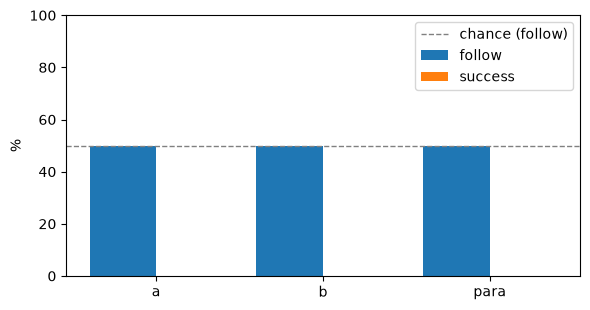

지시 대상이 놓인 쪽별 지시 따르기 비율(%): {'left': 100.0, 'right': 0.0}


,follow_rate,success_rate
set,,
a,50.0,0.0
b,50.0,0.0
para,50.0,0.0


In [10]:
# 관찰: 세 세트 30회 모두 지시문·물체 배치와 관계없이 항상 왼쪽 물체 쪽으로 갔고, 잡거나 옮기지 못했다 (전부 실패).
# 녹화 데이터에서도 30회 모두 베이스 회전(shoulder_pan)이 같은 방향(음수)으로 끝났다.
# 따라서 picked = 왼쪽에 놓인 물체: 짝수 회차(지시 대상이 왼쪽) = 지시 대상, 홀수 회차 = 다른 물체
for key, rows in lang_results.items():
    for r in rows:
        other = "b" if r["target"] == "a" else "a"
        left = r["target"] if r["target_side"] == "left" else other
        verb = "옮기지" if r["target"] == "a" else "집지"
        if left == r["target"]:
            note = f"지시 대상({OBJECTS[left]})이 왼쪽이라 그쪽으로 갔지만 {verb} 못함. 다른 회차처럼 위치(왼쪽)만 보고 간 것으로 보임"
        else:
            note = f"지시와 반대로 왼쪽의 {OBJECTS[left]} 쪽으로 감. 지시문과 관계없이 항상 왼쪽으로 감"
        r.update(picked=left, success=False, note=note)
lang_results["b"][5]["note"] += " (이 회차는 ←로 한 번 폐기 후 다시 녹화)"

lang_df = pd.concat([pd.DataFrame(v).assign(set=k) for k, v in lang_results.items()], ignore_index=True)
filled = lang_df["picked"].notna()
lang_df["followed"] = (lang_df["picked"] == lang_df["target"]).where(filled)
lang_summary = (lang_df.assign(success=lang_df["success"].astype(float), followed=lang_df["followed"].astype(float))
                .groupby("set", sort=False)
                .agg(follow_rate=("followed", "mean"), success_rate=("success", "mean")) * 100).round(0)
side = (lang_df[filled].assign(followed=lang_df["followed"].astype(float))
        .groupby("target_side")["followed"].mean() * 100).round(0)

fig, ax = plt.subplots(figsize=(6, 3.2))
x = range(len(lang_summary))
ax.bar([i - 0.2 for i in x], lang_summary["follow_rate"], width=0.4, label="follow")
ax.bar([i + 0.2 for i in x], lang_summary["success_rate"], width=0.4, label="success")
ax.axhline(50, color="gray", ls="--", lw=1, label="chance (follow)")
ax.set_xticks(list(x)); ax.set_xticklabels(lang_summary.index); ax.set_ylim(0, 100)
ax.set_ylabel("%"); ax.legend(); plt.tight_layout(); plt.show()

print("지시 대상이 놓인 쪽별 지시 따르기 비율(%):", side.to_dict())
lang_summary

### 4-3. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
다음 장면을 GIF로 만들어 `images/`에 올리고 아래에 삽입한다.
- 같은 배치에서 지시문 A와 B에 따라 다른 물체를 옮긴 장면 (각 1개)
- 지시를 따르지 못했거나 실패한 장면 1개

지시문에 따라 다른 물체로 간 장면은 한 번도 없었다. 대신 **같은 배치(위치 쌍 1, 박스 왼쪽·큐브 오른쪽)에서 지시문만 바꾼 두 회차**를 골랐다. 두 지시 모두 왼쪽(박스) 쪽으로 간다.

- 세트 A 에피소드 0: "Move the box" (지시 대상 = 박스, 왼쪽)

![lang_a](images/hw5_lang_a.gif)

- 세트 B 에피소드 1: "Grab the black cube" (지시 대상 = 큐브, 오른쪽) — 큐브가 아니라 왼쪽 박스 쪽으로 감

![lang_b](images/hw5_lang_b.gif)

- 실패 장면, 바꿔 말하기 에피소드 5: "Pick up the black block." (지시 대상 = 큐브, 오른쪽) — 역시 왼쪽으로 감

![lang_fail](images/hw5_lang_fail.gif)

## 5. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다. 가능하면 4절의 수치나 영상 장면을 근거로 든다.

> 평가 조건의 한계: ACT·Diffusion은 시각 입력이 없던 과제 4 결과를 재사용했고, 노트북에서 캘리브레이션을 새로 했으며, 카메라 25 fps와 안전 제한(5°/스텝)으로 평가했다(4-1). 언어 지시 데이터셋도 지침과 달리 물체가 하나씩만 있는 기존 시연을 합쳐 만들었다(2-1).

**5-1. 가설 검증** — 1-3의 가설과 결과를 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.

세 가설 모두 맞지 않았다. 정책 비교에서는 SmolVLA도 10회 중 0회 성공(0%)이라, ACT·Diffusion(0%)보다 성공률이 높다고 할 수 없었다. 지시 따르기 비율은 A 50%, B 50%, 바꿔 말하기 50%로, A 70% 이상이라는 예상보다 낮았다. 이 50%는 정책이 지시를 따른 결과가 아니라, 늘 왼쪽으로 갔고 지시 대상이 왼쪽인 회차가 절반이라 생긴 숫자다. 바꿔 말하기에서 비율이 떨어질 것이라는 예상도 확인할 수 없었다. 학습한 지시문에서 이미 우연 수준이라 떨어질 여지가 없었다. 가설과 달라진 주된 원인은 두 가지로 본다. 첫째, 학습 데이터에 물체가 하나뿐인 장면만 있어 두 물체가 함께 있는 평가 장면이 학습 분포 밖이었다. 둘째, 노트북에서 추론이 느렸고(1665 ms) 캘리브레이션이 학습 때와 달라 동작 자체가 불안정했다.

**5-2. 사전학습의 효과** — 같은 데이터셋에서 SmolVLA는 ACT·Diffusion과 비교해 성공률과 동작에서 어떤 차이를 보였는가? 사전학습된 가중치에서 출발한 것이 어떤 영향을 주었다고 보는가?

성공률은 세 정책 모두 0%로 차이가 없었다. 다만 SmolVLA만 카메라 2대가 정상인 조건이었고, 그 조건에서 실제로 박스 쪽으로 다가갔다. 시각 입력이 없던 과제 4의 ACT가 제자리에 머문 것과는 다른 모습이다. 동작은 어깨·팔꿈치가 100° 이상 크게 오르내렸고 안전 제한에 자주 걸려 부드러움은 1이었다. 50스텝 청크를 실행한 뒤 다음 추론에 약 1.7초가 걸려, 20초 동안 기록된 프레임이 약 300개(약 15 Hz)에 그쳤다. 사전학습 가중치 덕분에 5000 step만으로 박스를 향하는 방향은 배웠다고 볼 수 있다. 하지만 미세조정 데이터 50개와 짧은 학습으로는 잡고 옮기는 정밀한 동작까지 익히지 못했다. 같은 조건에서 비교하려면 ACT·Diffusion도 정상 카메라로 다시 평가해야 한다.

**5-3. 지시 따르기** — 학습한 지시문에서 지시 따르기 비율은 우연 수준(50%)보다 확실히 높았는가? 지시 대상이 놓인 쪽(왼쪽/오른쪽)에 따라 비율이 달랐다면, 정책이 지시문과 위치 중 무엇에 더 의존했다고 보는가?

우연 수준보다 높지 않았다. A, B 모두 정확히 50%였다. 지시 대상이 놓인 쪽에 따라 보면, 왼쪽일 때 100%, 오른쪽일 때 0%다. 정책은 지시문을 쓰지 않고 **위치(항상 왼쪽)**에만 의존했다. 같은 배치(위치 쌍 1, 박스 왼쪽)에서 "Move the box"와 "Grab the black cube"를 줬을 때 두 번 모두 왼쪽 박스 쪽으로 간 장면이 이를 보여 준다(4-3 GIF). 학습 데이터의 move-box 시연 45개가 모두 왼쪽에 놓인 박스를 오른쪽으로 옮기는 동작이었다. 그래서 "왼쪽으로 가서 오른쪽으로 민다"는 동작이 지시문보다 강하게 학습된 것으로 본다.

**5-4. 지시 따르기와 성공의 구분** — 지시한 물체를 집었지만 상자에 넣지 못한 경우가 있었는가? 언어 이해의 실패와 동작 실행의 실패를 나눠서 설명하라.

지시한 물체 쪽으로 간 회차(짝수 회차 15번)는 있었지만, 지시한 물체를 잡거나 옮긴 회차는 없었다. 언어 이해 쪽에서는 지시문이 행동 선택에 전혀 영향을 주지 못했다. 지시 대상이 오른쪽인 회차는 모두 반대 물체로 갔다. 동작 실행 쪽에서는 지시 대상 쪽으로 간 회차에서도 그리퍼로 잡거나 목표 영역까지 밀지 못했다. 팔이 크게 오르내리며 덜컥거렸고, 추론하는 동안 약 1.7초씩 멈춘 것이 원인으로 보인다. 따라서 이번 결과는 언어 이해 실패와 동작 실행 실패가 **동시에** 일어난 것이다. 동작 실행이 먼저 안정되어야 언어 이해를 제대로 평가할 수 있다.

**5-5. 바꿔 말하기** — 바꿔 말한 지시문에서 결과가 어떻게 달라졌는가? 50 에피소드, 지시문 2개라는 데이터 규모를 고려할 때 정책이 언어를 "이해"했다고 말할 수 있는가?

바꿔 말하기 세트도 50%(왼쪽 100%, 오른쪽 0%)로 학습한 지시문과 똑같았다. "Push the box to the right."와 "Pick up the black block." 모두 왼쪽으로 갔다. 문장이 달라져도 행동이 그대로라는 것은, 정책이 문장을 일반화했다기보다 처음부터 문장을 쓰지 않았다는 뜻이다. 지시문 2개, 50 에피소드(그중 B 5개)에 각 장면에 물체가 하나뿐인 데이터로는, 정책이 언어를 "이해"했다고 말할 수 없다. 언어를 쓰게 하려면 두 물체를 함께 놓고 위치를 바꿔 가며 지시문별로 비슷한 수의 시연을 모아야 한다. 그래야 지시문 말고는 어느 물체를 고를지 알 수 없는 데이터가 된다.

**5-6. 정책 선택** — 과제 3~5의 결과를 종합할 때, 학습 비용, 추론 속도, 성공률, 언어 지시 필요 여부를 고려해 본인 태스크에는 어떤 정책이 적합한가?

내 태스크(박스 하나를 왼쪽에서 오른쪽으로 옮기기)에는 **ACT**가 적합하다고 본다. 성공률은 세 정책 모두 0%라 차이를 가리지 못했다. 학습 시간은 같은 5000 step에서 ACT 약 21분, Diffusion 약 18분, SmolVLA 약 31분이었다. 평가 노트북(MX450)에서 1회 추론은 ACT 123 ms, Diffusion(DDIM 10) 753 ms, SmolVLA 1665 ms로 ACT가 가장 빨랐다. 장면에 물체가 하나뿐이라 언어 지시도 필요 없다. 이번 평가처럼 GPU가 약한 환경에서는 추론 지연이 바로 동작 끊김으로 이어지므로, 빠르고 가벼운 ACT가 유리하다. 여러 물체 중 하나를 골라야 하는 태스크로 바뀐다면 SmolVLA가 필요하다. 그때는 두 물체를 함께 놓은 데이터를 지침대로 새로 모으고, 학습 PC 수준의 GPU나 비동기 추론(RTC)으로 추론 지연을 줄여야 한다.


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [11]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

def policy_ok(rid):
    return file_ok(rid, "config.json", "model") and file_ok(rid, "model.safetensors", "model")

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in [*EVAL_DATASETS.values(), *LANG_EVAL_DATASETS.values()]),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "언어 지시 데이터셋 에피소드 50개, 지시문 2개 이상": bool(lang_info) and lang_info.get("total_episodes") == 50
                                                     and (lang_info.get("total_tasks") or 0) >= 2,
    "SmolVLA (비교) 업로드됨": policy_ok(SMOLVLA_REPO),
    "SmolVLA (언어 지시) 업로드됨": policy_ok(SMOLVLA_LANG_REPO),
    "정책별 학습 데이터셋 일치 (3-3)": dataset_ok,
    "task 문장이 TASK·INSTRUCTIONS와 일치하고 영어로 작성됨 (3-3)": task_ok and instr_ok and english_ok,
}
for k in CONDITIONS:
    check_items[f"{LABELS[k]} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"{LABELS[k]} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"{LABELS[k]} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
for key, rid in LANG_EVAL_DATASETS.items():
    info = load_json(rid, "meta/info.json", repo_type="dataset")
    rows = lang_results[key]
    check_items[f"언어 지시 [{key}] 평가 데이터셋 에피소드 10개"] = bool(info) and info.get("total_episodes") == 10
    check_items[f"언어 지시 [{key}] 결과 10개 입력"] = all(r["picked"] in ("a", "b", "none") and r["success"] is not None for r in rows)
    check_items[f"언어 지시 [{key}] 실패 회차에 원인 기재"] = all(
        r["note"].strip() for r in rows if r["success"] is False or (r["picked"] is not None and r["picked"] != r["target"]))

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] 학습 데이터셋 접근 가능 (public)
[통과] 언어 지시 데이터셋 에피소드 50개, 지시문 2개 이상
[통과] SmolVLA (비교) 업로드됨
[통과] SmolVLA (언어 지시) 업로드됨
[통과] 정책별 학습 데이터셋 일치 (3-3)
[통과] task 문장이 TASK·INSTRUCTIONS와 일치하고 영어로 작성됨 (3-3)
[통과] ACT (chunk50) 평가 데이터셋 에피소드 10개
[통과] ACT (chunk50) 회차별 결과 10개 입력
[통과] ACT (chunk50) 실패 회차에 원인 기재
[통과] Diffusion 평가 데이터셋 에피소드 10개
[통과] Diffusion 회차별 결과 10개 입력
[통과] Diffusion 실패 회차에 원인 기재
[통과] SmolVLA 평가 데이터셋 에피소드 10개
[통과] SmolVLA 회차별 결과 10개 입력
[통과] SmolVLA 실패 회차에 원인 기재
[통과] 언어 지시 [a] 평가 데이터셋 에피소드 10개
[통과] 언어 지시 [a] 결과 10개 입력
[통과] 언어 지시 [a] 실패 회차에 원인 기재
[통과] 언어 지시 [b] 평가 데이터셋 에피소드 10개
[통과] 언어 지시 [b] 결과 10개 입력
[통과] 언어 지시 [b] 실패 회차에 원인 기재
[통과] 언어 지시 [para] 평가 데이터셋 에피소드 10개
[통과] 언어 지시 [para] 결과 10개 입력
[통과] 언어 지시 [para] 실패 회차에 원인 기재

모두 통과
